In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, beta
from scipy.optimize import brentq
import matplotlib.patches as patches
from numpy.random import default_rng
rng = default_rng()
%matplotlib inline

# introduction to "unfolded" verification diagrams

Performance diagrams (Roebber 2009) and Doolittle-Kraemer diagrams (see intro_doolittle_kraemer_diagram.ipynb) share a geometry: lines of constant frequency bias (or bias-odds) are rays from the origin, and summary scores such as $CSI$ or $\phi$ are constant along curves that wrap around the perfect-forecast corner $(1,1)$. An "unfolded" diagram replaces the $(x,y)$ coordinates with (angle, score): the x-axis is the angle of a bias measure, $\theta=\arctan(bias)$ or $\theta=\arctan(bias_{odds})$, and the y-axis is a summary score. This "opens the book":

- the origin, where all the rays meet, is stretched into the whole bottom edge (score = 0)
- the perfect corner $(1,1)$ becomes the apex at $\theta=45^{\circ}$, score = 1
- the $POD=1$ and $SR=1$ edges (or their skill versions) become the two sides of a "roof" above which no 2x2 table exists

The same angle can be paired with a discrimination measure ($d'$, which "unfolds" a ROC diagram) or a displacement (the two-circle model of Baldwin and Kain 2006). For each space, this notebook derives the 2x2 contingency table at any point, the reachable and no-skill regions, and checks the math numerically. Examples use synthetic forecasts and NWS tornado-warning performance for 51 offices grouped by mean warning duration (2012–2025, provided by H. Brooks).

| Space | x-axis | y-axis | parent diagram | base rate needed to place a point? | model assumption |
|---|---|---|---|---|---|
| CSI–bias | $\arctan(bias)$ | $CSI$ | performance | no (only for background and regions) | none |
| $\phi$–bias-odds | $\arctan(bias_{odds})$ | $\phi$ | Doolittle-Kraemer | yes | none |
| $d'$–bias-odds | $\arctan(bias_{odds})$ | $d'=Z(POD)-Z(POFD)$ | ROC | yes | none to place a point; binormal curves draw the grid |
| displacement–bias-odds | $\arctan(bias_{odds})$ | displacement $D$ | Baldwin and Kain (2006) | yes | two-circle geometry |

Related displays exist: Hogan and Mason (2012) skill–bias diagrams, and Slocum et al. (2023, appendix), who plot $HSS$ against frequency bias with $F_1$ shading at several base rates. See "prior work" at the end.

## 2x2 contingency table and score functions

As in the other intro notebooks, $a$ = hits, $b$ = false alarms, $c$ = missed events, $d$ = correct nulls (proportions, $a+b+c+d=1$), base rate $\bar x=a+c$, mean forecast $\bar f=a+b$, frequency bias $B=\bar f/\bar x$, and bias-odds $=\frac{\bar f/(1-\bar f)}{\bar x/(1-\bar x)}=\frac{POD_{skill}}{SR_{skill}}$.

In [2]:
# score functions from the 2x2 contingency table
def pod(a,b,c,d):
    return a/(a+c)

def sr(a,b,c,d):
    return a/(a+b)

def pofd(a,b,c,d):
    return b/(b+d)

def csi(a,b,c,d):
    return a/(a+b+c)

def bias(a,b,c,d):
    return (a+b)/(a+c)

def biasodds(a,b,c,d):
    return (a+b)*(b+d)/(a+c)/(c+d)

def podskill(a,b,c,d):
    return (a*d-b*c)/(a+c)/(c+d)

def srskill(a,b,c,d):
    return (a*d-b*c)/(a+b)/(b+d)

def phi(a,b,c,d):
    return (a*d-b*c)/np.sqrt((a+c)*(c+d)*(a+b)*(b+d))

def hss(a,b,c,d):
    return 2.*(a*d-b*c)/((a+c)*(c+d)+(a+b)*(b+d))

def dprime(a,b,c,d):
    return norm.ppf(a/(a+c))-norm.ppf(b/(b+d))

# random 2x2 tables with positive skill, used for the numerical checks below
tables=rng.dirichlet([1.,1.,1.,1.],size=200000)
ta,tb,tc,td=tables.T
keep=(ta*td-tb*tc)>0
ta,tb,tc,td=ta[keep],tb[keep],tc[keep],td[keep]
print(len(ta),'random tables with positive skill')

99663 random tables with positive skill


## example data

**Synthetic forecasts:** the same generator as intro_performance_diagram.ipynb and intro_doolittle_kraemer_diagram.ipynb, but with $\bar x=\bar f=0.1$ so that the synthetic curve shares a base rate with the warning data.

**Tornado warnings by duration:** POD and SR for the 51 NWS offices that averaged more than 20 tornado warnings per year in 2012–2025, sorted by mean warning duration and split into 5 groups (10, 10, 11, 10, 10 offices). The group means are Harold Brooks's group performance values (loaded from byduration_groupmean.csv in verification_figures_for_harold.ipynb); they are not simple averages of the office values. NWS reports POD and FAR without a base rate; following Brooks (2004), these examples assume $\bar x=0.1$, interpreted as the fraction of "difficult" warning situations that produce a tornado. The last section tests how the conclusions change with $\bar x$.

In [3]:
# functions to generate synthetic forecasts and observations and compute the 2x2 contingency table
# (same as intro_performance_diagram.ipynb)

def synth_data(nn,xbar,fbar,sharp,rhoxf):
    cov = np.array([[1.,rhoxf ], [rhoxf,1.]])
    pts = rng.multivariate_normal([0., 0.], cov, size=nn)
    obs_bin=np.zeros_like(pts[:,0])
    xthresh=norm.ppf(1-xbar,0.,1.)
    obs_bin[pts[:,0]>=xthresh]=1.
    sx21=xbar*(1.-xbar)
    sf21=sharp*sx21
    nu1=fbar*(1-fbar)/sf21-1.
    alpha1=fbar*nu1
    beta1=(1.-fbar)*nu1
    fcst_beta=beta.ppf(norm.cdf(pts[:,1],0.,1.), alpha1,beta1)
    fthresh=np.quantile(fcst_beta,1.-fbar)
    fcst_bin=fcst_beta>=fthresh
    return obs_bin,fcst_beta,fcst_bin

def calc_2x2_table(fcst,obs,thresholds):
    nthresh=len(thresholds)
    aa=np.full(nthresh,np.nan)
    bb=np.full(nthresh,np.nan)
    cc=np.full(nthresh,np.nan)
    dd=np.full(nthresh,np.nan)
    for j in np.arange(nthresh):
        fthresh=thresholds[j]
        fcst_bin=fcst>=fthresh
        nn=float(len(obs))
        aa[j]=np.sum(obs*fcst_bin)/nn
        bb[j]=np.sum((1.-obs)*fcst_bin)/nn
        cc[j]=np.sum(obs*(1.-fcst_bin))/nn
        dd[j]=np.sum((1.-obs)*(1.-fcst_bin))/nn
    df=pd.DataFrame(data=np.array([thresholds,aa,bb,cc,dd]).T,columns=['thresh','a','b','c','d'])
    return df

xbar=0.1
nn=100000
obs_pts,fcst_pts,fcst_bin=synth_data(nn,xbar,xbar,0.7,0.8)
threshs=np.quantile(fcst_pts,np.linspace(0.01,0.99,50))
df=calc_2x2_table(fcst_pts,obs_pts,threshs)
for name,f in [('POD',pod),('SR',sr),('POFD',pofd),('CSI',csi),('BIAS',bias),('PODskill',podskill),('SRskill',srskill),('PHI',phi),('DPRIME',dprime)]:
    df[name]=f(df.a,df.b,df.c,df.d)
df['THETA_BO']=np.degrees(np.arctan(df.PODskill/df.SRskill))
print('synthetic base rate:',np.round(np.mean(obs_pts),4))

synthetic base rate: 0.1004


In [4]:
# tornado warnings by duration group (H. Brooks): office POD and SR, group 0 = shortest mean duration
offices=pd.DataFrame({'SR':[0.439331, 0.546493, 0.490196, 0.203046, 0.532178, 0.369369, 0.322936, 0.268124, 0.441057, 0.370262, 0.307836, 0.417891, 0.304762, 0.496528, 0.217557, 0.416323, 0.384289, 0.418919, 0.168067, 0.402957, 0.321238, 0.259053, 0.242215, 0.334443, 0.324153, 0.403061, 0.337917, 0.356989, 0.260563, 0.329412, 0.200581, 0.131757, 0.148594, 0.209169, 0.266212, 0.292419, 0.239300, 0.326761, 0.158798, 0.262338, 0.422492, 0.204774, 0.266174, 0.365801, 0.223919, 0.343042, 0.339806, 0.185442, 0.271930, 0.231683, 0.202667],
                      'POD':[0.745020, 0.636842, 0.696721, 0.565891, 0.642857, 0.634981, 0.651408, 0.642857, 0.563380, 0.658537, 0.576433, 0.661871, 0.539773, 0.479167, 0.608856, 0.673077, 0.611650, 0.459615, 0.483871, 0.494670, 0.690537, 0.617647, 0.504425, 0.624615, 0.534173, 0.525806, 0.482412, 0.518106, 0.466912, 0.483986, 0.478632, 0.479452, 0.426523, 0.413793, 0.578947, 0.581395, 0.629213, 0.530973, 0.463235, 0.545946, 0.593407, 0.467532, 0.466102, 0.495298, 0.462069, 0.431280, 0.502890, 0.566667, 0.431818, 0.473510, 0.435065],
                      'group':[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]})
# group means (Harold Brooks's group performance; from byduration_groupmean.csv)
groups=pd.DataFrame({'SR':[0.378249,0.358330,0.312704,0.232092,0.253417],
                     'POD':[0.657924,0.575433,0.542804,0.529574,0.474539],
                     'group':[0,1,2,3,4]})
colorlist=['#023EFF','#FF7C00','#1AC938','#E8000B','#8B2BE2']
leg=['#1-10','#11-20','#21-31','#32-41','#42-51']

def add_scores(dfin,xbar):
    # 2x2 table from POD, SR and an assumed base rate (as in intro_performance_diagram.ipynb)
    out=dfin.copy()
    out['a']=xbar*out.POD
    out['b']=xbar*(out.POD/out.SR-out.POD)
    out['c']=xbar*(1.-out.POD)
    out['d']=1.-out.a-out.b-out.c
    for name,f in [('CSI',csi),('BIAS',bias),('PODskill',podskill),('SRskill',srskill),('PHI',phi),('DPRIME',dprime),('POFD',pofd)]:
        out[name]=f(out.a,out.b,out.c,out.d)
    out['THETA_BO']=np.degrees(np.arctan(out.PODskill/out.SRskill))
    return out

off_x=add_scores(offices,xbar)
grp_x=add_scores(groups,xbar)

def plot_groups(ax,dfo,dfg,xcol,ycol,xf=lambda v: v):
    # office points joined to their group mean (larger symbol), as in the figures sent to H. Brooks
    for i in range(5):
        oi=dfo[dfo.group==i]; mi=dfg[dfg.group==i].iloc[0]
        for _,r in oi.iterrows():
            ax.plot([xf(mi[xcol]),xf(r[xcol])],[mi[ycol],r[ycol]],color=colorlist[i],marker='o',ms=2.5,lw=0.4,alpha=0.45)
        ax.plot(xf(mi[xcol]),mi[ycol],'o',color=colorlist[i],ms=8,mec='k',mew=0.5,zorder=10,label=leg[i])

grp_x[['group','POD','SR','BIAS','CSI','PODskill','SRskill','PHI','DPRIME','THETA_BO']].round(3)

,group,POD,SR,BIAS,CSI,PODskill,SRskill,PHI,DPRIME,THETA_BO
0,0,0.658,0.378,1.739,0.316,0.586,0.309,0.426,1.581,62.180
1,1,0.575,0.358,1.606,0.283,0.494,0.287,0.377,1.393,59.852
2,2,0.543,0.313,1.736,0.248,0.447,0.236,0.325,1.222,62.122
3,3,0.530,0.232,2.282,0.192,0.391,0.147,0.239,0.935,69.401
4,4,0.475,0.253,1.873,0.198,0.353,0.170,0.245,0.950,64.254


## CSI–bias space (unfolded performance diagram)

A point needs only $POD$ and $SR$:

$B=\frac{POD}{SR}, \qquad \frac{1}{CSI}=\frac{1}{POD}+\frac{1}{SR}-1$

Solving $CSI=\frac{a}{a+b+c}$ with $a+b=\bar xB$ and $a+c=\bar x$ gives the 2x2 table at any point $(\theta=\arctan B,\ CSI)$:

$a=\bar x\,\frac{CSI\,(1+B)}{1+CSI},\quad b=\bar xB-a,\quad c=\bar x-a,\quad d=1-\bar x-b$

$POD=\frac{CSI\,(1+B)}{1+CSI},\qquad SR=\frac{POD}{B}$

Unreachable regions (some table element would be negative):

- the roof, $CSI>\min(B,1/B)$: the left side $CSI=B$ is $b=0$ (no false alarms, the $SR=1$ edge of the performance diagram); the right side $CSI=1/B$ is $c=0$ (no misses, the $POD=1$ edge)
- the lower-right corner, $CSI<\bar xB-(1-\bar x)$ (from $d\ge0$), which only matters for $B>(1-\bar x)/\bar x$; this is the performance diagram's unachievable region (Boyd et al. 2012)
- the right wall, $B\le 1/\bar x$ (the mean forecast cannot exceed 1)

No-skill: a random forecast with bias $B$ has $a=\bar x^2B$ ($SR=\bar x$), so

$CSI_{random}(B)=\frac{\bar xB}{1+B-\bar xB}$

and points below this curve are worse than random. The code checks each of these statements.

In [5]:
def table_csi_bias(B,C,xbar):
    a=xbar*C*(1.+B)/(1.+C)
    b=xbar*B-a
    c=xbar-a
    d=1.-xbar-b
    return a,b,c,d

# check: table recovered from (bias, CSI, base rate)
rec=table_csi_bias(bias(ta,tb,tc,td),csi(ta,tb,tc,td),ta+tc)
print('table recovered from (B, CSI, xbar):',all(np.allclose(u,v) for u,v in zip(rec,(ta,tb,tc,td))))

# check: region boundaries on a grid, for several base rates
for xb in [0.01,0.1,0.33,0.6]:
    Bg,Cg=np.meshgrid(np.linspace(0.001,1./xb-1e-6,1500),np.linspace(0.0005,0.9995,1500))
    ag,bg,cg,dg=table_csi_bias(Bg,Cg,xb)
    valid=(ag>=0)&(bg>=0)&(cg>=0)&(dg>=0)
    pred=(Cg<=np.minimum(Bg,1./Bg))&(Cg>=xb*Bg-(1.-xb))
    noskill=Cg<=xb*Bg/(1.+Bg-xb*Bg)
    print(f'xbar={xb}: reachable region matches formulas:',np.array_equal(valid,pred),
          '| SR<=xbar matches no-skill curve:',np.array_equal((ag/(ag+bg)<=xb)[valid],noskill[valid]))

table recovered from (B, CSI, xbar): True


xbar=0.01: reachable region matches formulas: True | SR<=xbar matches no-skill curve: True


xbar=0.1: reachable region matches formulas: True | SR<=xbar matches no-skill curve: True


xbar=0.33: reachable region matches formulas: True | SR<=xbar matches no-skill curve: True
xbar=0.6: reachable region matches formulas: True | SR<=xbar matches no-skill curve: True


synthetic forecasts: highest CSI = 0.392 at bias = 1.30 (arctan = 52.3 deg)


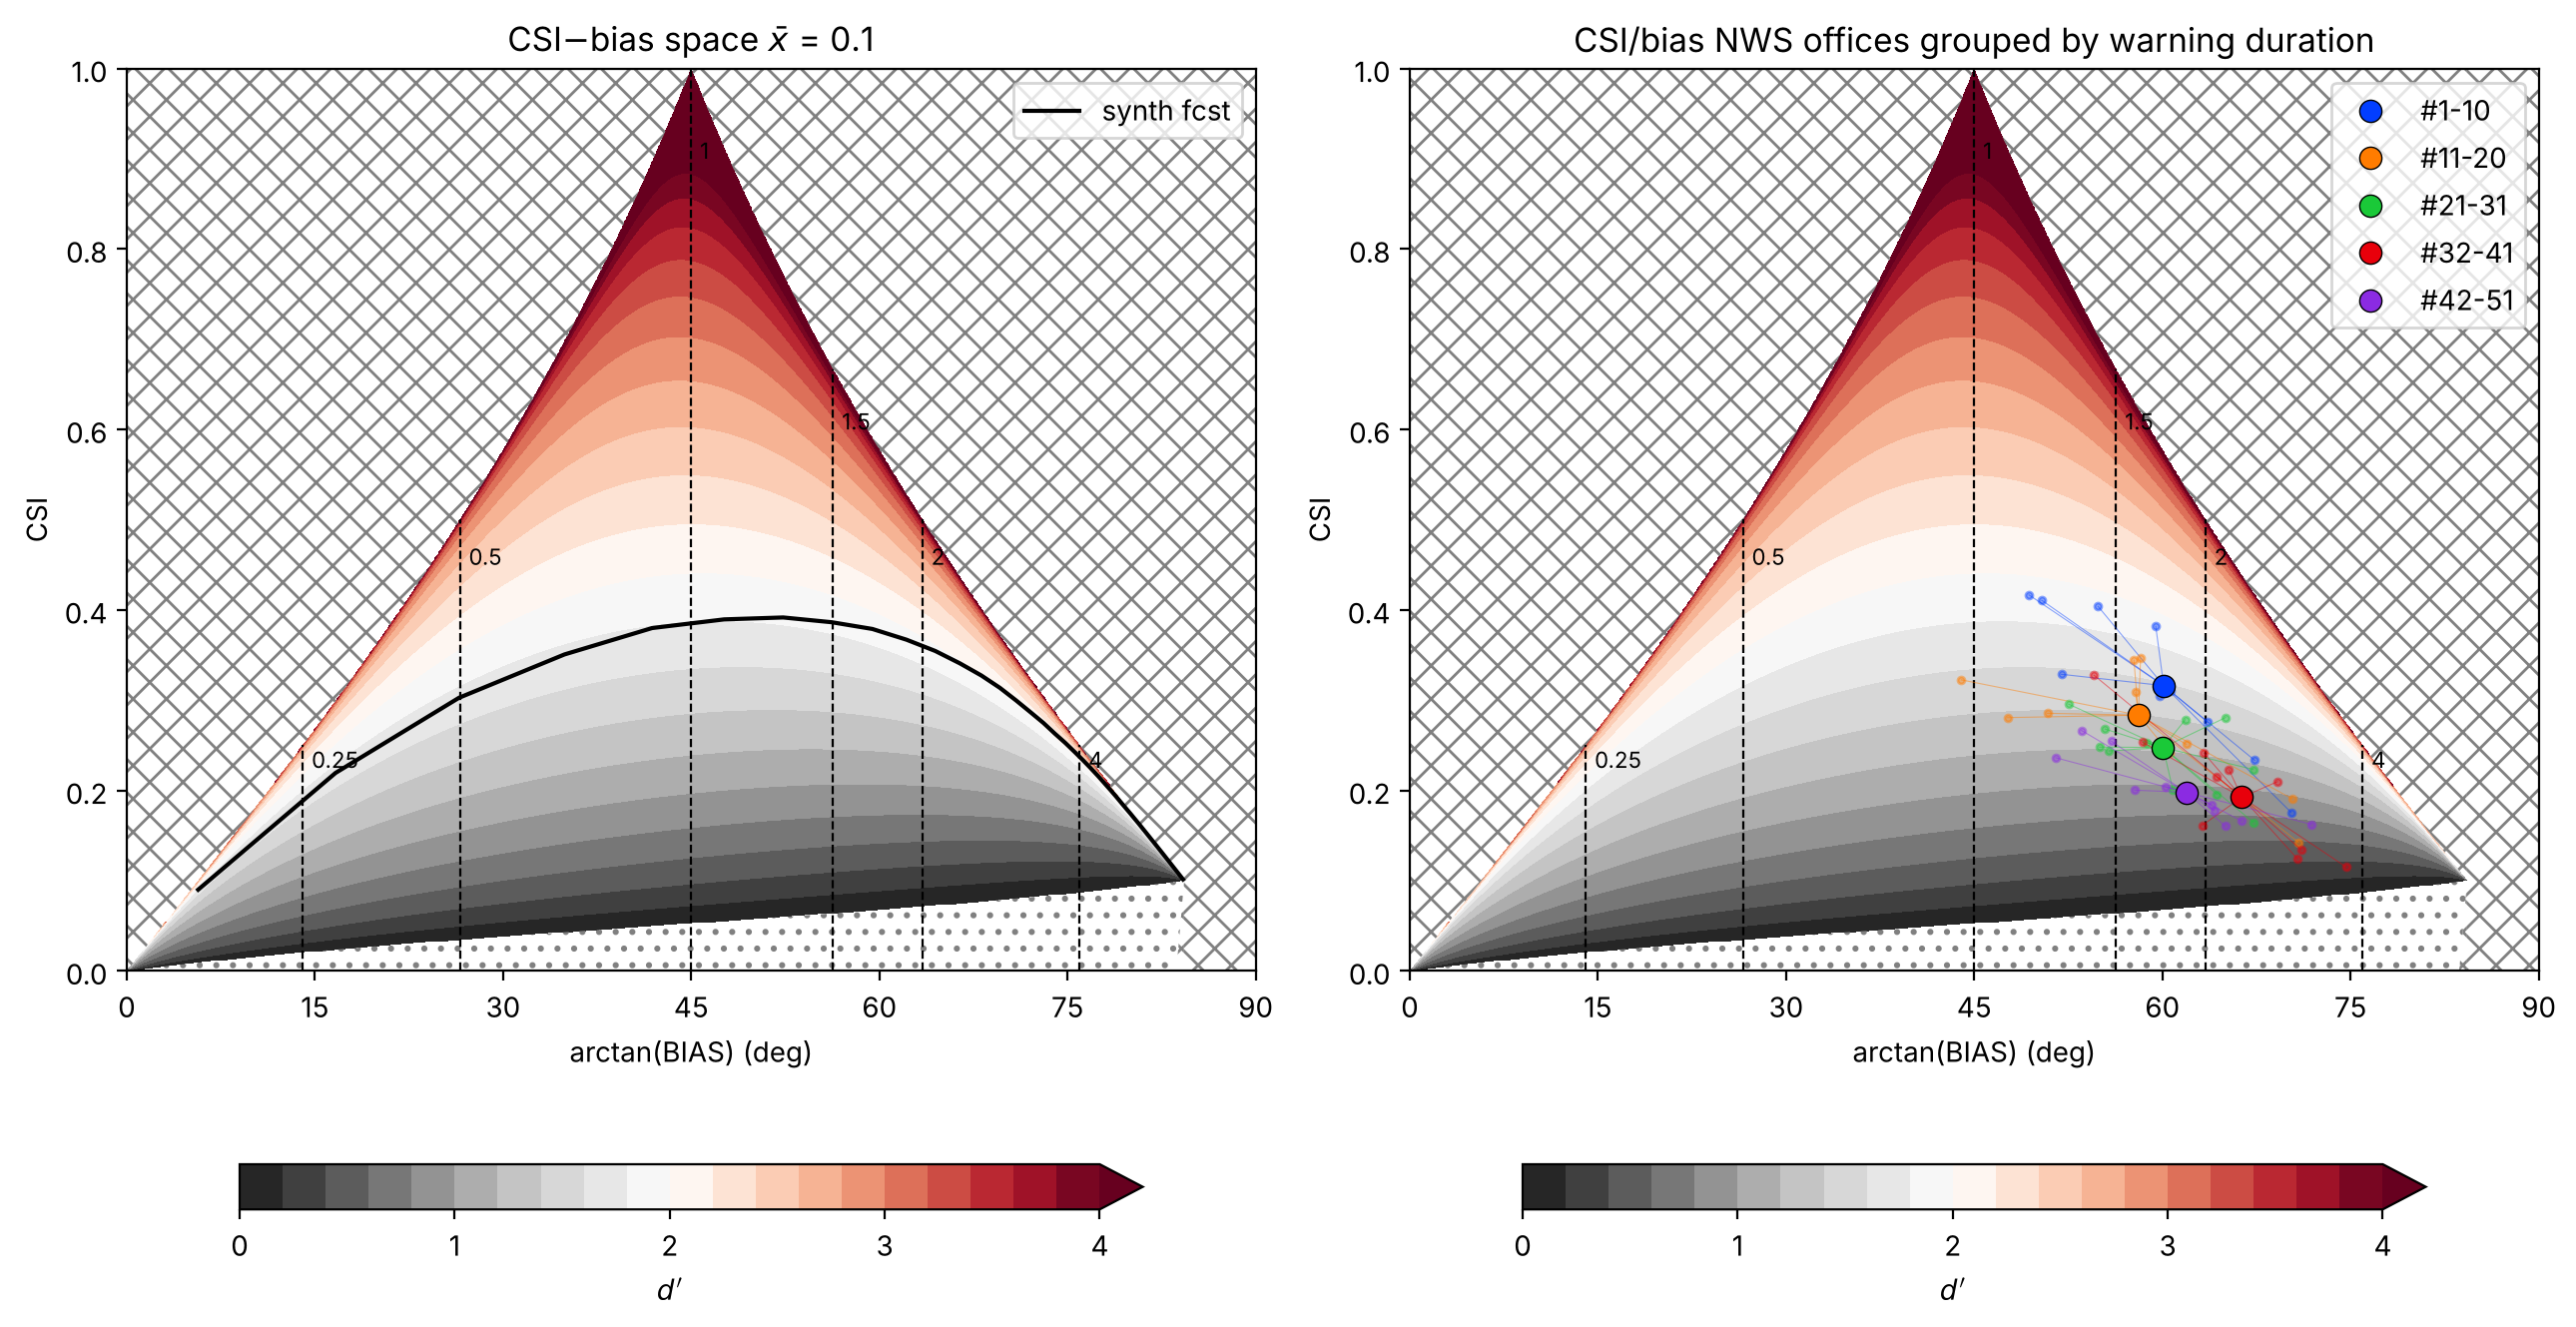

In [6]:
# CSI-bias space with d' in the background, synthetic forecasts and warning-duration groups (xbar = 0.1)

def csi_bias_axes(ax,xbar,fill=dprime,label=r"$d'$",lvls=np.linspace(0.,4.,21),ticks=np.linspace(0.,4.,5),extend='max'):
    th1=np.linspace(0.0005,np.arctan(1./xbar)-1e-6,1500)
    c1=np.linspace(0.0005,0.9995,1000)
    TH,CS=np.meshgrid(th1,c1)
    Bg=np.tan(TH)
    a,b,c,d=table_csi_bias(Bg,CS,xbar)
    bad=(a<0)|(b<0)|(c<0)|(d<0)|(a/(a+b)<=xbar)
    F=fill(a,b,c,d); F[bad]=np.nan
    sc=ax.contourf(np.degrees(TH),CS,F,levels=lvls,cmap='RdGy_r',extend=extend)
    plt.colorbar(sc,ax=ax,orientation='horizontal',shrink=0.8,label=label,ticks=ticks)
    # unreachable regions (cross-hatch) and no-skill region (dots)
    Bl=np.tan(th1)
    ax.fill_between(np.degrees(th1),np.minimum(Bl,1./Bl),1.,facecolor='none',hatch='xx',edgecolor='0.5',lw=0)
    low=np.maximum(xbar*Bl-(1.-xbar),0.)
    ax.fill_between(np.degrees(th1),0.,low,facecolor='none',hatch='xx',edgecolor='0.5',lw=0)
    ax.fill_between(np.degrees(th1),low,xbar*Bl/(1.+Bl-xbar*Bl),facecolor='none',hatch='..',edgecolor='0.5',lw=0)
    ax.axvspan(np.degrees(np.arctan(1./xbar)),90.,facecolor='none',hatch='xx',edgecolor='0.5',lw=0)
    for bl in [0.25,0.5,1.,1.5,2.,4.]:
        ax.plot([np.degrees(np.arctan(bl))]*2,[0.,min(bl,1./bl)],'k--',lw=0.8)
        ax.text(np.degrees(np.arctan(bl))+0.7,0.9*min(bl,1./bl),f'{bl:g}',fontsize=8)
    ax.set_xlim(0.,90.); ax.set_ylim(0.,1.)
    ax.set_xticks(np.arange(0,91,15))
    ax.set_xlabel('arctan(BIAS) (deg)'); ax.set_ylabel('CSI')
    ax.set_title(r'CSI$-$bias space $\bar x$ = '+f'{xbar}')

fig,axs=plt.subplots(1,2,figsize=(13,7))
csi_bias_axes(axs[0],xbar)
axs[0].plot(np.degrees(np.arctan(df.BIAS)),df.CSI,'k-',lw=1.5,label='synth fcst')
axs[0].legend(loc='upper right')
csi_bias_axes(axs[1],xbar)
plot_groups(axs[1],off_x,grp_x,'BIAS','CSI',xf=lambda v: np.degrees(np.arctan(v)))
axs[1].set_title('CSI/bias NWS offices grouped by warning duration')
axs[1].legend(loc='upper right')
plt.tight_layout()
imx=df.CSI.idxmax()
print(f'synthetic forecasts: highest CSI = {df.CSI[imx]:.3f} at bias = {df.BIAS[imx]:.2f} (arctan = {np.degrees(np.arctan(df.BIAS[imx])):.1f} deg)')

Bias lines are vertical, so the roof makes the trade-off visible: the further a forecast's bias is from 1, the lower its highest possible CSI. The synthetic curve runs from the lower left (high threshold, few "yes" forecasts) to the lower right (low threshold); the cell above prints where it reaches its highest CSI.

## $\phi$–bias-odds space (unfolded Doolittle-Kraemer diagram)

This is the Doolittle-Kraemer diagram in "polar" form. With $t=\tan\theta=bias_{odds}=POD_{skill}/SR_{skill}$ and the radius $\phi=\sqrt{POD_{skill}\,SR_{skill}}$ (the geometric mean of the axes, Yule's $\phi$):

$POD_{skill}=\phi\sqrt{t},\qquad SR_{skill}=\frac{\phi}{\sqrt{t}}$

The 2x2 table then follows from the Doolittle-Kraemer table (`table_from_skill()` below, from intro_doolittle_kraemer_diagram.ipynb), so placing a point needs $\bar x$. Two other scores have closed forms in these coordinates:

$HSS=\frac{2\phi\sqrt{t}}{1+t},\qquad bias=\frac{t}{1+\bar x(t-1)}$

Bias lines are vertical, but their positions depend on $\bar x$. The only unreachable region is the roof, $\phi>\min(\sqrt t,1/\sqrt t)$ (left side $SR_{skill}=1$, right side $POD_{skill}=1$), and it is the **same for every base rate**. No-skill is the bottom edge, $\phi=0$; forecasts worse than random have $\phi<0$.

In [7]:
def table_from_skill(sr_s,pod_s,xbar):
    ratio=pod_s/sr_s
    fbar=ratio/((1.-xbar)/xbar+ratio)
    a=xbar*(1.-fbar)*pod_s+fbar*xbar
    b=fbar*(1.-xbar)*(1.-sr_s)
    c=xbar*(1.-fbar)*(1.-pod_s)
    d=(1.-xbar)*(1.-fbar)+fbar*(1.-xbar)*sr_s
    return a,b,c,d

def table_phi_theta(theta,ph,xbar):
    t=np.tan(theta)
    return table_from_skill(ph/np.sqrt(t),ph*np.sqrt(t),xbar)

t_bo=biasodds(ta,tb,tc,td); p_=phi(ta,tb,tc,td); xb_=ta+tc
print('POD_skill = phi*sqrt(t), SR_skill = phi/sqrt(t):',np.allclose(podskill(ta,tb,tc,td),p_*np.sqrt(t_bo)) and np.allclose(srskill(ta,tb,tc,td),p_/np.sqrt(t_bo)))
print('HSS = 2 phi sqrt(t)/(1+t):',np.allclose(hss(ta,tb,tc,td),2.*p_*np.sqrt(t_bo)/(1.+t_bo)))
print('bias = t/(1+xbar(t-1)):',np.allclose(bias(ta,tb,tc,td),t_bo/(1.+xb_*(t_bo-1.))))
rec=table_phi_theta(np.arctan(t_bo),p_,xb_)
print('table recovered from (theta, phi, xbar):',all(np.allclose(u,v) for u,v in zip(rec,(ta,tb,tc,td))))
for xb in [0.01,0.1,0.33,0.9]:
    Tg,Pg=np.meshgrid(np.linspace(0.001,np.pi/2-0.001,1200),np.linspace(0.0005,1.5,1200))
    ag,bg,cg,dg=table_phi_theta(Tg,Pg,xb)
    valid=(ag>=0)&(bg>=0)&(cg>=0)&(dg>=0)
    print(f'xbar={xb}: reachable <=> phi <= min(sqrt(t),1/sqrt(t)):',np.array_equal(valid,Pg<=np.minimum(np.sqrt(np.tan(Tg)),1./np.sqrt(np.tan(Tg)))))

POD_skill = phi*sqrt(t), SR_skill = phi/sqrt(t): True
HSS = 2 phi sqrt(t)/(1+t): True
bias = t/(1+xbar(t-1)): True
table recovered from (theta, phi, xbar): True
xbar=0.01: reachable <=> phi <= min(sqrt(t),1/sqrt(t)): True
xbar=0.1: reachable <=> phi <= min(sqrt(t),1/sqrt(t)): True
xbar=0.33: reachable <=> phi <= min(sqrt(t),1/sqrt(t)): True


xbar=0.9: reachable <=> phi <= min(sqrt(t),1/sqrt(t)): True


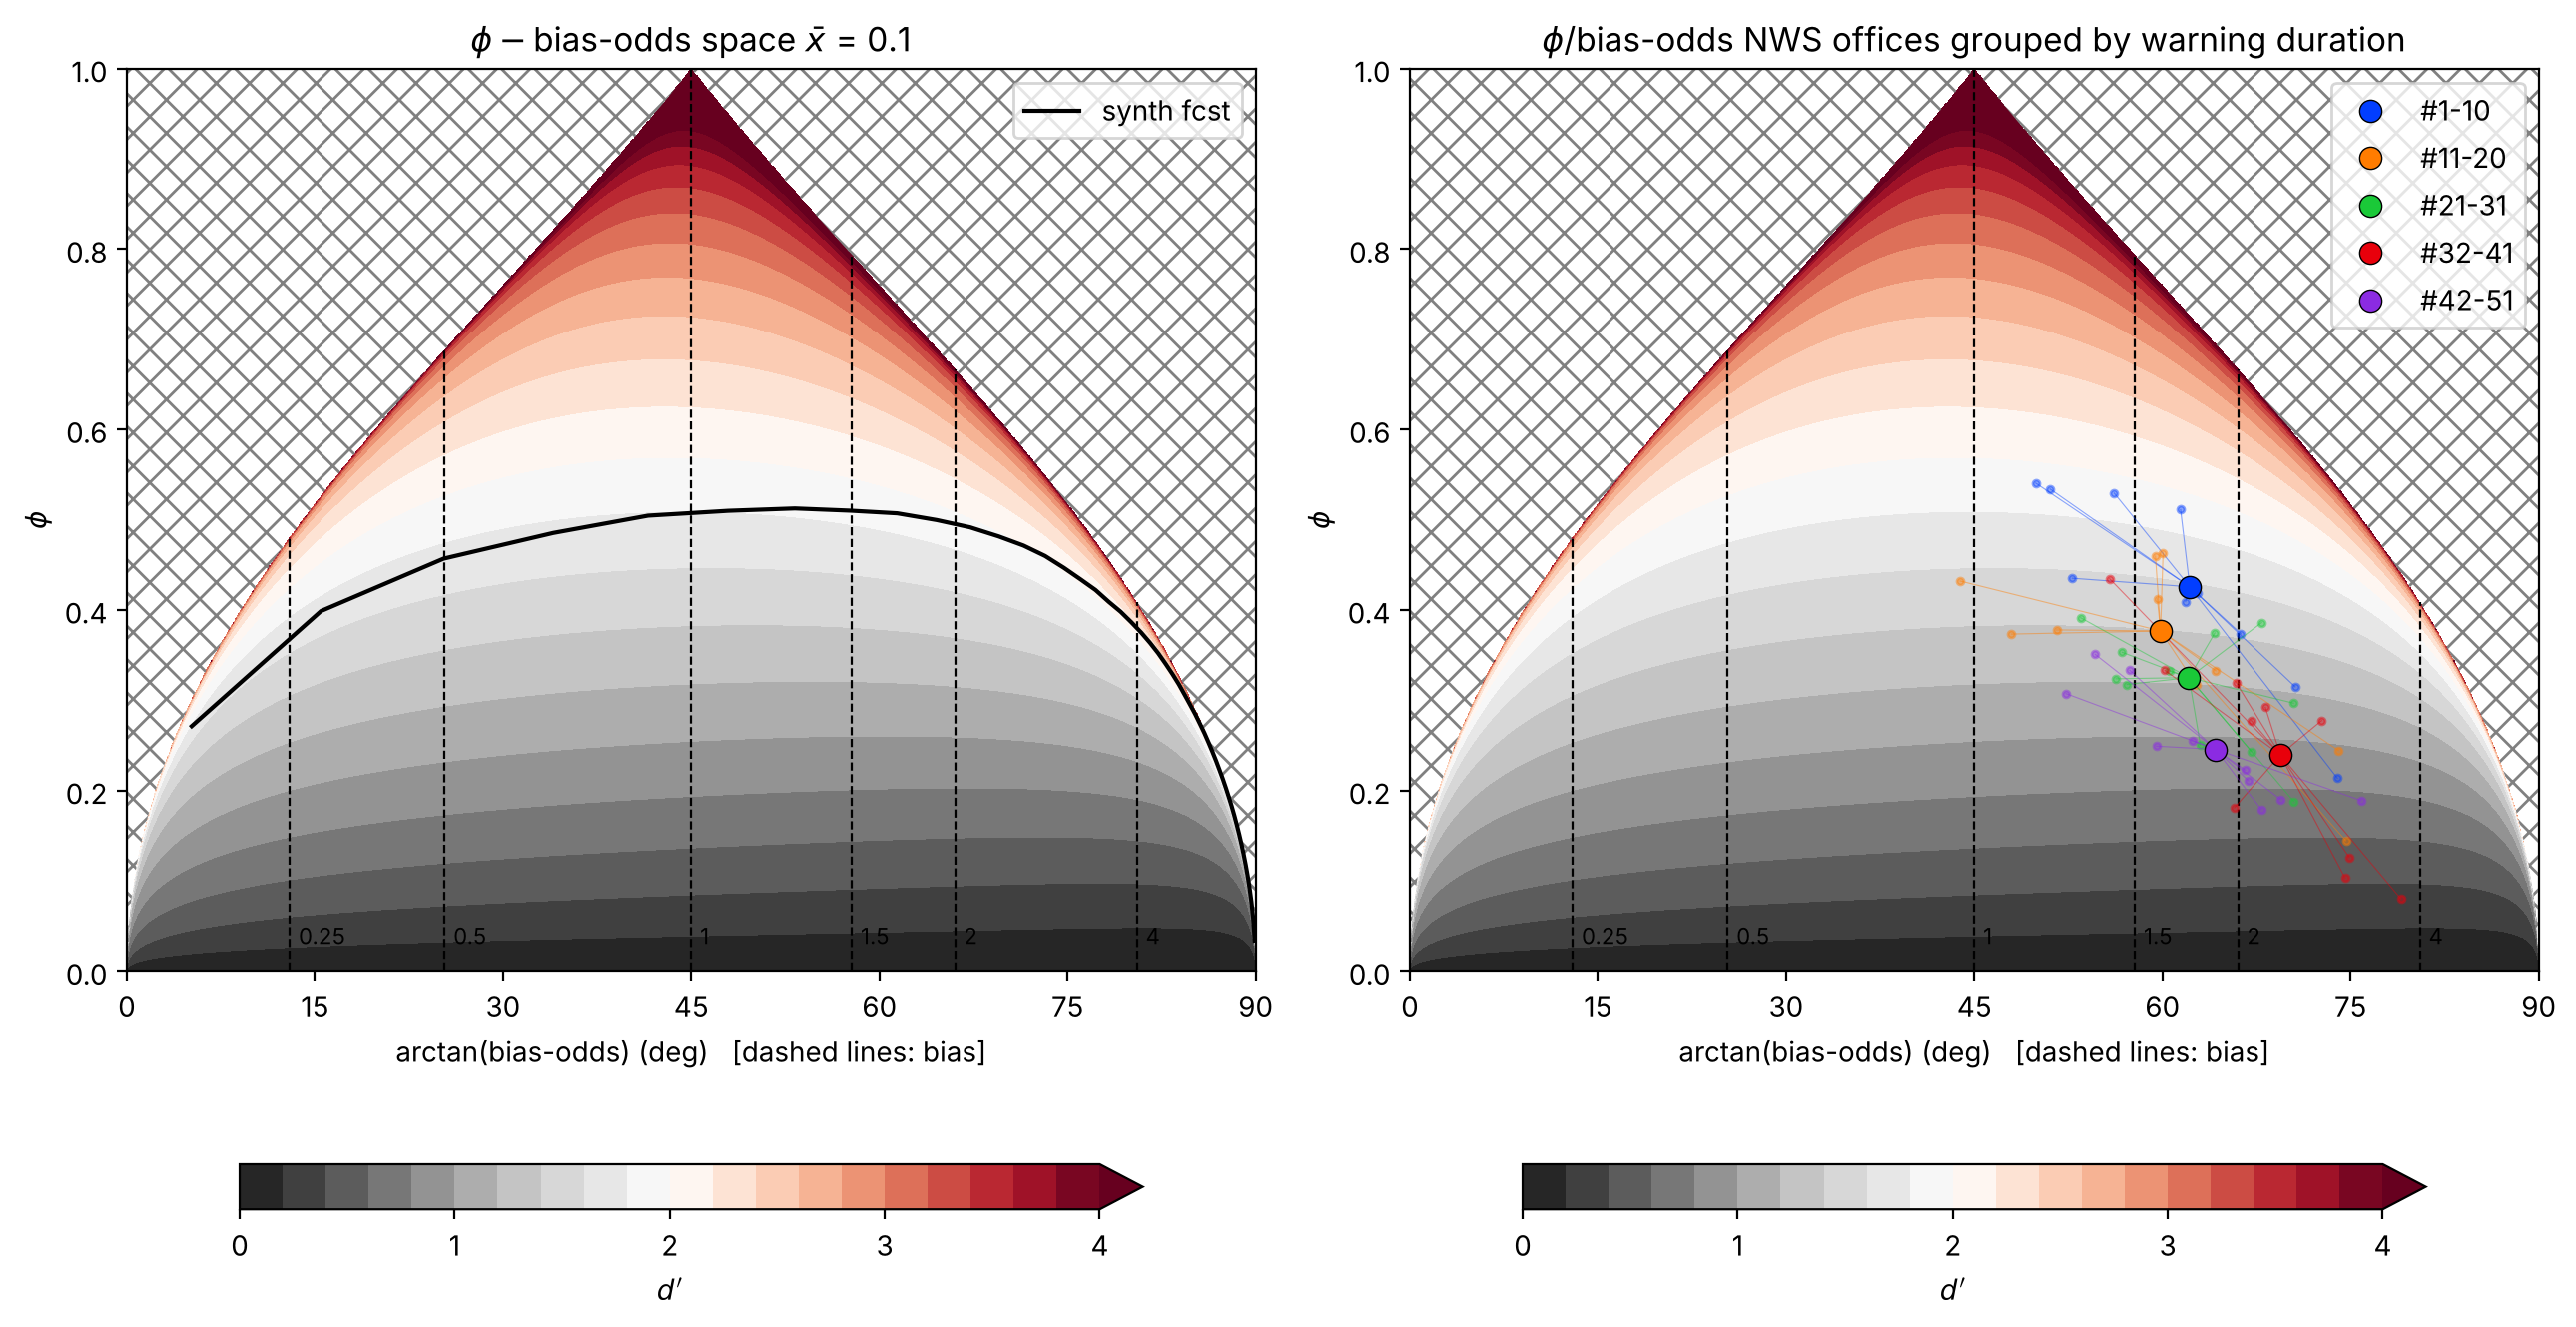

In [8]:
# phi-bias-odds space with d' in the background (xbar = 0.1)

def phi_theta_axes(ax,xbar,fill=dprime,label=r"$d'$",lvls=np.linspace(0.,4.,21),ticks=np.linspace(0.,4.,5),extend='max'):
    th1=np.linspace(0.001,np.pi/2-0.001,1200)
    p1=np.linspace(0.0005,0.9995,1000)
    TH,PH=np.meshgrid(th1,p1)
    a,b,c,d=table_phi_theta(TH,PH,xbar)
    bad=(a<0)|(b<0)|(c<0)|(d<0)
    F=fill(a,b,c,d); F[bad]=np.nan
    sc=ax.contourf(np.degrees(TH),PH,F,levels=lvls,cmap='RdGy_r',extend=extend)
    plt.colorbar(sc,ax=ax,orientation='horizontal',shrink=0.8,label=label,ticks=ticks)
    t1=np.tan(th1); roof=np.minimum(np.sqrt(t1),1./np.sqrt(t1))
    ax.fill_between(np.degrees(th1),roof,1.,facecolor='none',hatch='xx',edgecolor='0.5',lw=0)
    for bl in [0.25,0.5,1.,1.5,2.,4.]:
        tt=bl*(1.-xbar)/(1.-bl*xbar)          # bias-odds for this bias
        if bl<1./xbar:
            ax.plot([np.degrees(np.arctan(tt))]*2,[0.,min(np.sqrt(tt),1./np.sqrt(tt))],'k--',lw=0.8)
            ax.text(np.degrees(np.arctan(tt))+0.7,0.03,f'{bl:g}',fontsize=8)
    ax.set_xlim(0.,90.); ax.set_ylim(0.,1.)
    ax.set_xticks(np.arange(0,91,15))
    ax.set_xlabel('arctan(bias-odds) (deg)   [dashed lines: bias]'); ax.set_ylabel(r'$\phi$')
    ax.set_title(r'$\phi-$bias-odds space $\bar x$ = '+f'{xbar}')

fig,axs=plt.subplots(1,2,figsize=(13,7))
phi_theta_axes(axs[0],xbar)
axs[0].plot(df.THETA_BO,df.PHI,'k-',lw=1.5,label='synth fcst')
axs[0].legend(loc='upper right')
phi_theta_axes(axs[1],xbar)
plot_groups(axs[1],off_x,grp_x,'THETA_BO','PHI')
axs[1].set_title(r'$\phi$/bias-odds NWS offices grouped by warning duration')
axs[1].legend(loc='upper right')
plt.tight_layout()

## "opening the book": the same features before and after unfolding

Matching colors mark the same features on each parent diagram (left) and its unfolded space (right): the $SR=1$ edge (red) and $POD=1$ edge (blue) become the two sides of the roof, the perfect corner (star) becomes the apex, the neighborhood of the origin (green) becomes the bottom band, bias rays (dashed) become verticals, and $CSI$ or $\phi$ contours (gray) become horizontal lines.

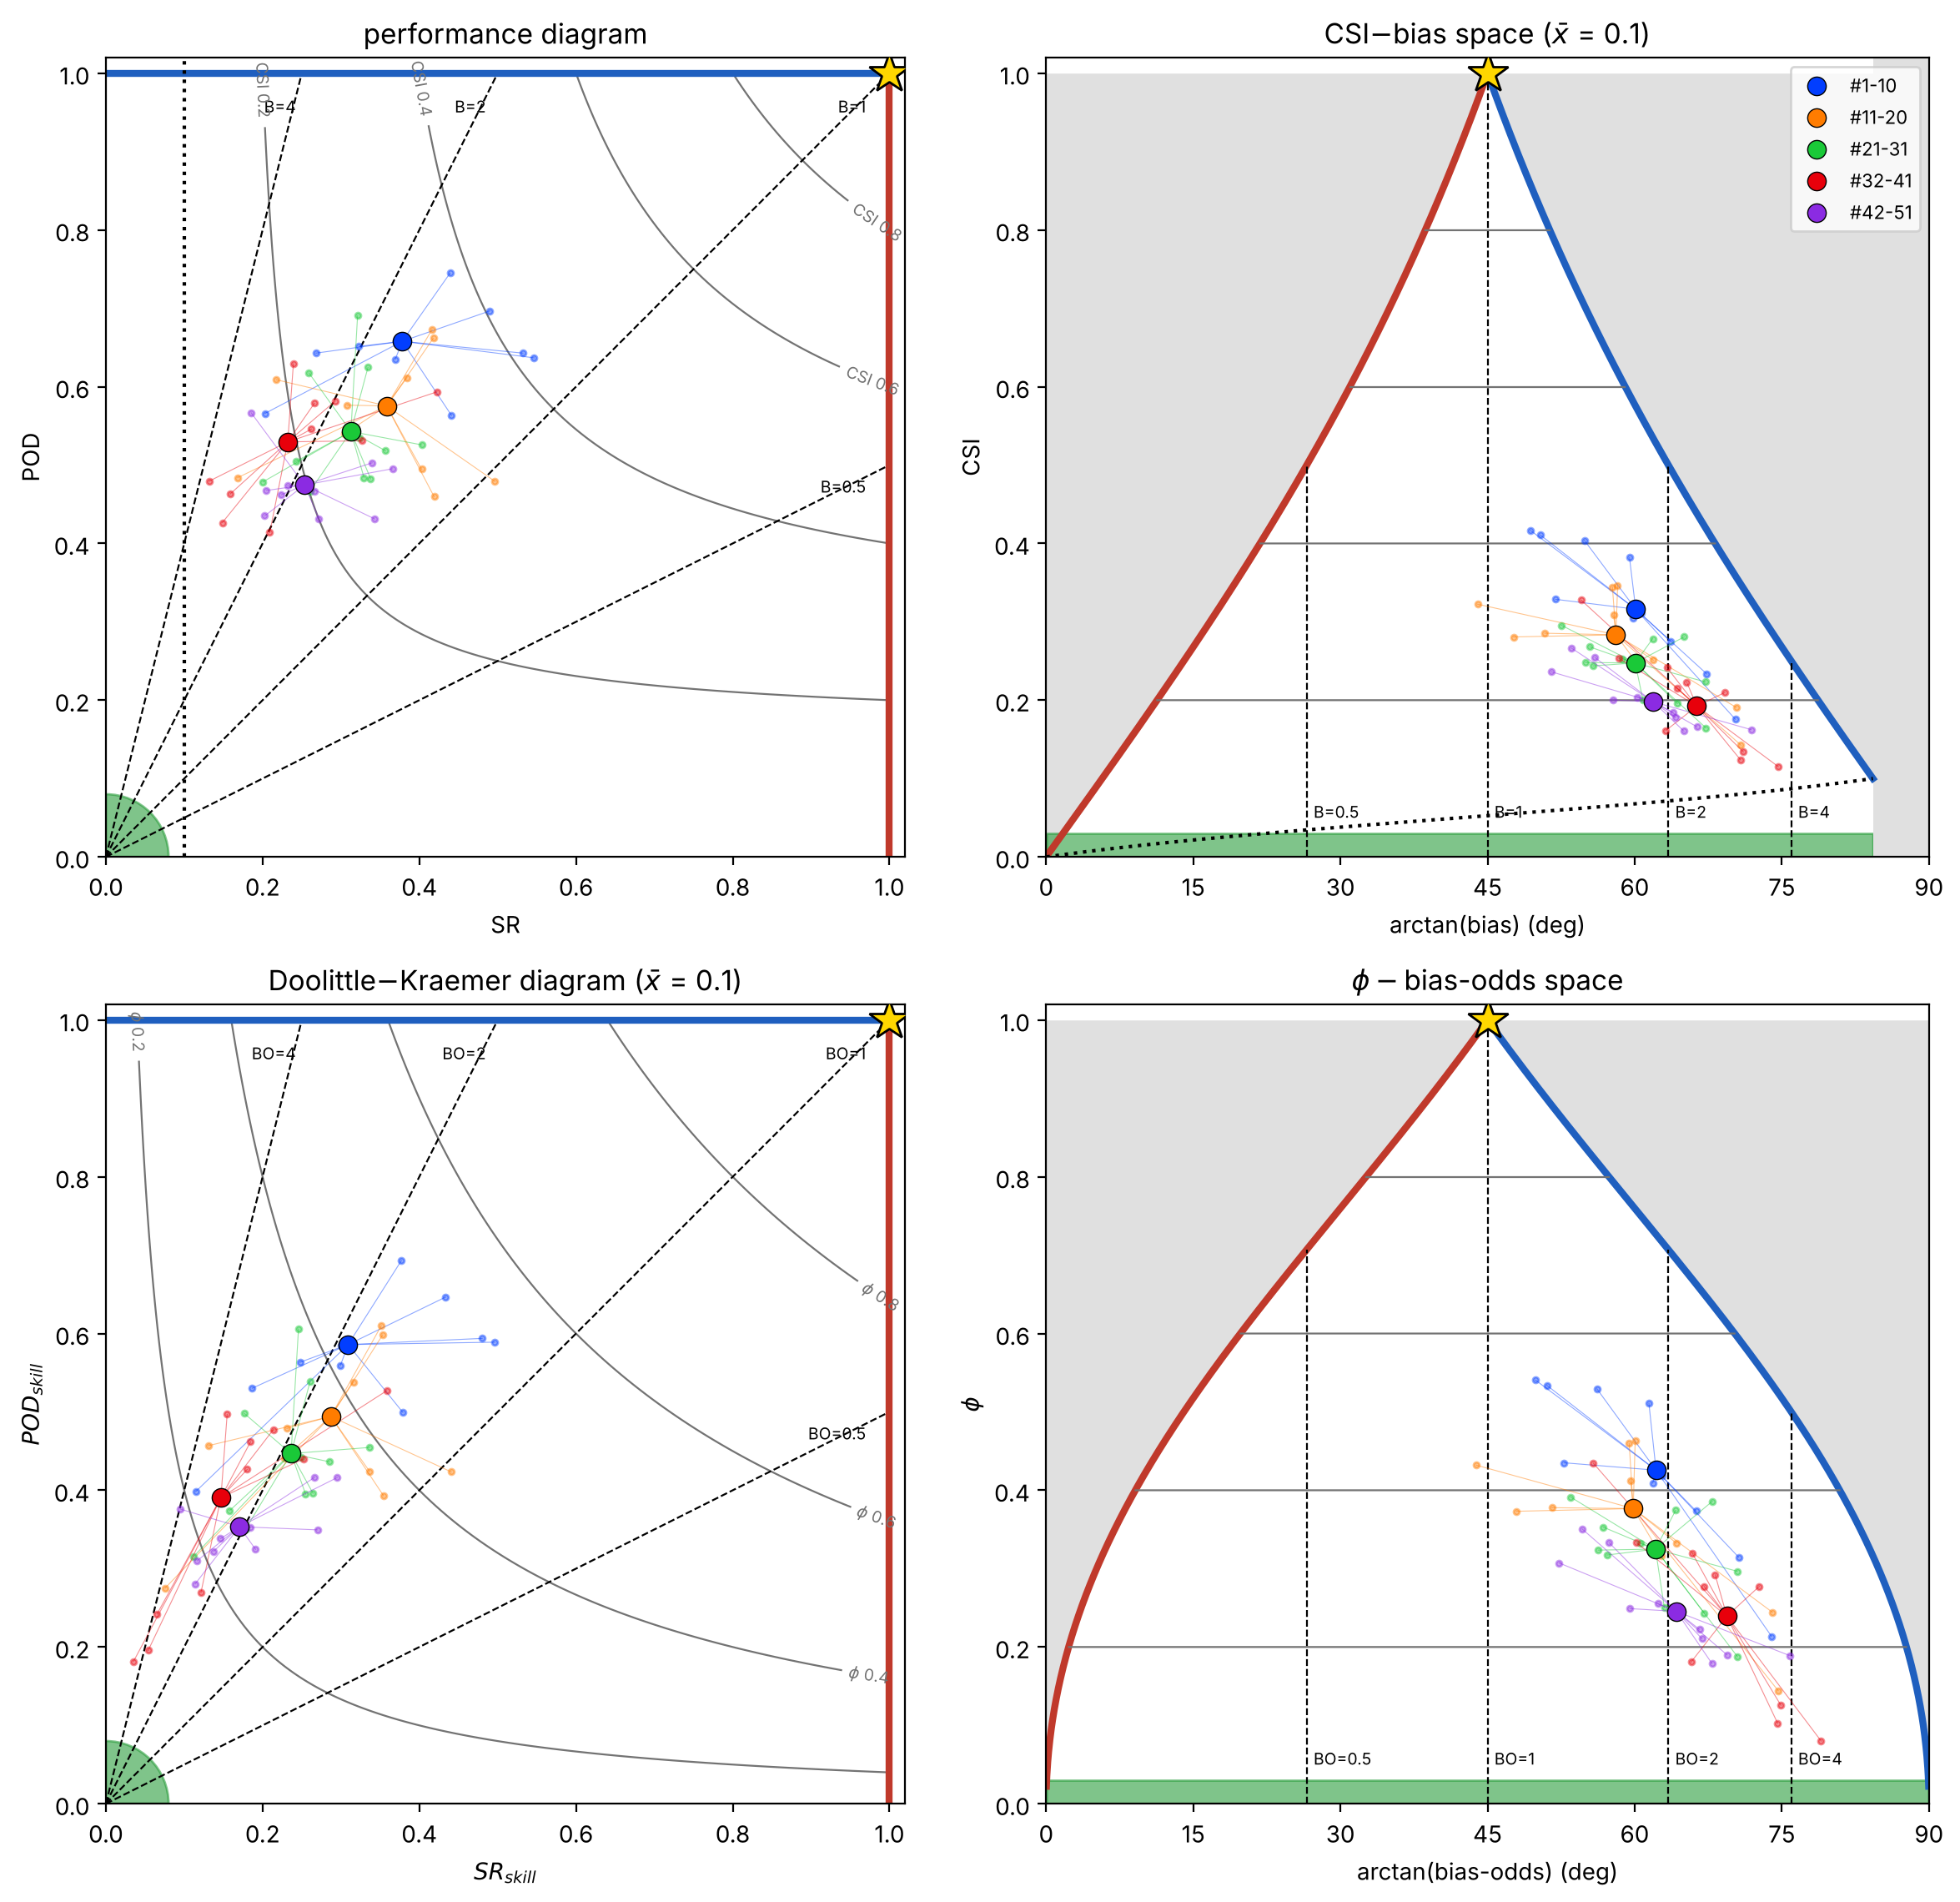

In [9]:
RED,BLUE,GRN='#c0392b','#1f5fbf','#2a9d3c'
bias_lv=[0.5,1,2,4]; sc_lv=[0.2,0.4,0.6,0.8]
s=np.linspace(0.0005,1,1500); S,P=np.meshgrid(s,s)

def parent(ax,Z,lab,xlab,ylab,title,raylab):
    cs=ax.contour(S,P,Z,levels=sc_lv,colors='0.45',linewidths=0.8); ax.clabel(cs,fmt=lab+' %.1f',fontsize=7)
    for bl in bias_lv:
        ax.plot([0,min(1,1/bl)],[0,min(1,bl)],'k--',lw=0.8)
        ax.text(min(1,1/bl)*0.97,min(1,bl)*0.97,f'{raylab}={bl:g}',fontsize=7,ha='right',va='top')
    ax.plot([1,1],[0,1],color=RED,lw=3); ax.plot([0,1],[1,1],color=BLUE,lw=3)
    ax.add_patch(patches.Wedge((0,0),0.08,0,90,color=GRN,alpha=0.6))
    ax.plot(1,1,'*',color='gold',ms=18,mec='k',zorder=12)
    ax.set(xlim=(0,1.02),ylim=(0,1.02),xlabel=xlab,ylabel=ylab,aspect='equal',title=title)

def unfolded(ax,th,roof,score_lab,xlab,title,vert_th,vert_top,vlab):
    ax.fill_between(np.degrees(th),roof,1,color='0.88',lw=0)
    t=np.tan(th)
    ax.plot(np.degrees(th[t<=1]),roof[t<=1],color=RED,lw=3); ax.plot(np.degrees(th[t>=1]),roof[t>=1],color=BLUE,lw=3)
    ax.fill_between(np.degrees(th),0,0.03,color=GRN,alpha=0.6)
    for v,top,l in zip(vert_th,vert_top,vlab):
        ax.plot([v,v],[0,top],'k--',lw=0.8); ax.text(v+0.7,0.05,l,fontsize=7)
    for cl in sc_lv:
        ok=roof>=cl; ax.plot(np.degrees(th[ok]),np.full(ok.sum(),cl),color='0.45',lw=0.8)
    ax.plot(45,1,'*',color='gold',ms=18,mec='k',zorder=12)
    ax.set(xlim=(0,90),ylim=(0,1.02),xlabel=xlab,ylabel=score_lab,title=title); ax.set_xticks(range(0,91,15))

fig,axs=plt.subplots(2,2,figsize=(12,11.5))
parent(axs[0,0],1/(1/S+1/P-1),'CSI','SR','POD','performance diagram','B')
axs[0,0].axvline(xbar,color='k',ls=':',lw=1.5)
plot_groups(axs[0,0],off_x,grp_x,'SR','POD')
th=np.linspace(0.0005,np.arctan(1/xbar),2000); Bt=np.tan(th)
unfolded(axs[0,1],th,np.minimum(Bt,1/Bt),'CSI','arctan(bias) (deg)',r'CSI$-$bias space ($\bar x$ = 0.1)',
         [np.degrees(np.arctan(b)) for b in bias_lv],[min(b,1/b) for b in bias_lv],[f'B={b:g}' for b in bias_lv])
axs[0,1].plot(np.degrees(th),xbar*Bt/(1+Bt-xbar*Bt),'k:',lw=1.5)
axs[0,1].axvspan(np.degrees(np.arctan(1/xbar)),90,color='0.88',lw=0)
plot_groups(axs[0,1],off_x,grp_x,'BIAS','CSI',xf=lambda v: np.degrees(np.arctan(v)))
parent(axs[1,0],np.sqrt(S*P),r'$\phi$',r'$SR_{skill}$',r'$POD_{skill}$',r'Doolittle$-$Kraemer diagram ($\bar x$ = 0.1)','BO')
plot_groups(axs[1,0],off_x,grp_x,'SRskill','PODskill')
th=np.linspace(0.0005,np.pi/2-0.0005,2000); tt=np.tan(th)
unfolded(axs[1,1],th,np.minimum(np.sqrt(tt),1/np.sqrt(tt)),r'$\phi$','arctan(bias-odds) (deg)',r'$\phi-$bias-odds space',
         [np.degrees(np.arctan(b)) for b in bias_lv],[min(np.sqrt(b),1/np.sqrt(b)) for b in bias_lv],[f'BO={b:g}' for b in bias_lv])
plot_groups(axs[1,1],off_x,grp_x,'THETA_BO','PHI')
axs[0,1].legend(loc='upper right',fontsize=8)
plt.tight_layout()

## $d'$–bias-odds space (unfolded ROC diagram)

On a ROC diagram, curves of constant $d'=Z(POD)-Z(POFD)$ are equal-variance binormal ROC curves, and changing the forecast threshold slides a point along one of them. This space straightens each curve into a horizontal line ($y=d'$) and measures position along it by the bias-odds angle ($x=\theta$). With a threshold variable $z$:

$POD=\Phi\left(z+\tfrac{d'}{2}\right),\quad POFD=\Phi\left(z-\tfrac{d'}{2}\right),\quad \bar f=\bar x\,POD+(1-\bar x)\,POFD,\quad \tan\theta=\frac{\bar f/(1-\bar f)}{\bar x/(1-\bar x)}$

The binormal model is only a convenient way to draw the grid. Any 2x2 table has a $d'$ and a $\theta$, and $(\theta,d',\bar x)$ fixes the table uniquely: $\bar f$ increases strictly with $z$ (its derivative is $\bar x\varphi(z+d'/2)+(1-\bar x)\varphi(z-d'/2)>0$, with $\varphi$ the normal density), so one value of $z$ matches each $\theta$ (found below by root finding). Placing a point therefore needs no model assumption, but it does need $\bar x$.

Regions: no unreachable region (the whole strip $0^{\circ}<\theta<90^{\circ}$, $d'>0$ is valid for every $\bar x$); no-skill is the bottom edge, $d'=0$.

In [10]:
def table_theta_dprime(theta,dp,xbar):
    # solve for the threshold z that gives bias-odds = tan(theta) on the d' curve
    target=np.log(np.tan(theta))
    def g(z):
        f=xbar*norm.cdf(z+0.5*dp)+(1.-xbar)*norm.cdf(z-0.5*dp)
        with np.errstate(divide='ignore'):   # f rounds to 0 or 1 at the ends of the bracket
            return np.log(f)-np.log1p(-f)-np.log(xbar/(1.-xbar))-target
    z=brentq(g,-30.,30.,xtol=1e-14)
    P=norm.cdf(z+0.5*dp); F=norm.cdf(z-0.5*dp)
    return xbar*P,(1.-xbar)*F,xbar*(1.-P),(1.-xbar)*(1.-F)

# check: round trip for 2000 random tables (avoid POD or POFD extremely close to 0 or 1)
idx=rng.choice(len(ta),3000,replace=False)
P_,F_=pod(ta,tb,tc,td)[idx],pofd(ta,tb,tc,td)[idx]
idx=idx[(P_>1e-4)&(P_<1-1e-4)&(F_>1e-4)&(F_<1-1e-4)][:2000]
th_=np.arctan(biasodds(ta,tb,tc,td)[idx]); dp_=dprime(ta,tb,tc,td)[idx]
rec=np.array([table_theta_dprime(th_[k],dp_[k],(ta+tc)[idx][k]) for k in range(len(idx))])
print('table recovered from (theta, d\', xbar) for',len(idx),'random tables:',np.allclose(rec,np.stack([ta[idx],tb[idx],tc[idx],td[idx]],1),atol=1e-8))

# check: bias-odds increases with z at fixed d' (|z|<=6; beyond that the normal CDF rounds off in double precision)
zz=np.linspace(-6,6,4001)
mono=all(np.all(np.diff(np.log(xb*norm.cdf(zz+d/2)+(1-xb)*norm.cdf(zz-d/2))-np.log1p(-(xb*norm.cdf(zz+d/2)+(1-xb)*norm.cdf(zz-d/2))))>0)
         for d in [0.01,0.5,1,2,4] for xb in [0.01,0.1,0.5,0.9])
print('bias-odds increases monotonically with threshold:',mono)

table recovered from (theta, d', xbar) for 2000 random tables: True
bias-odds increases monotonically with threshold: True


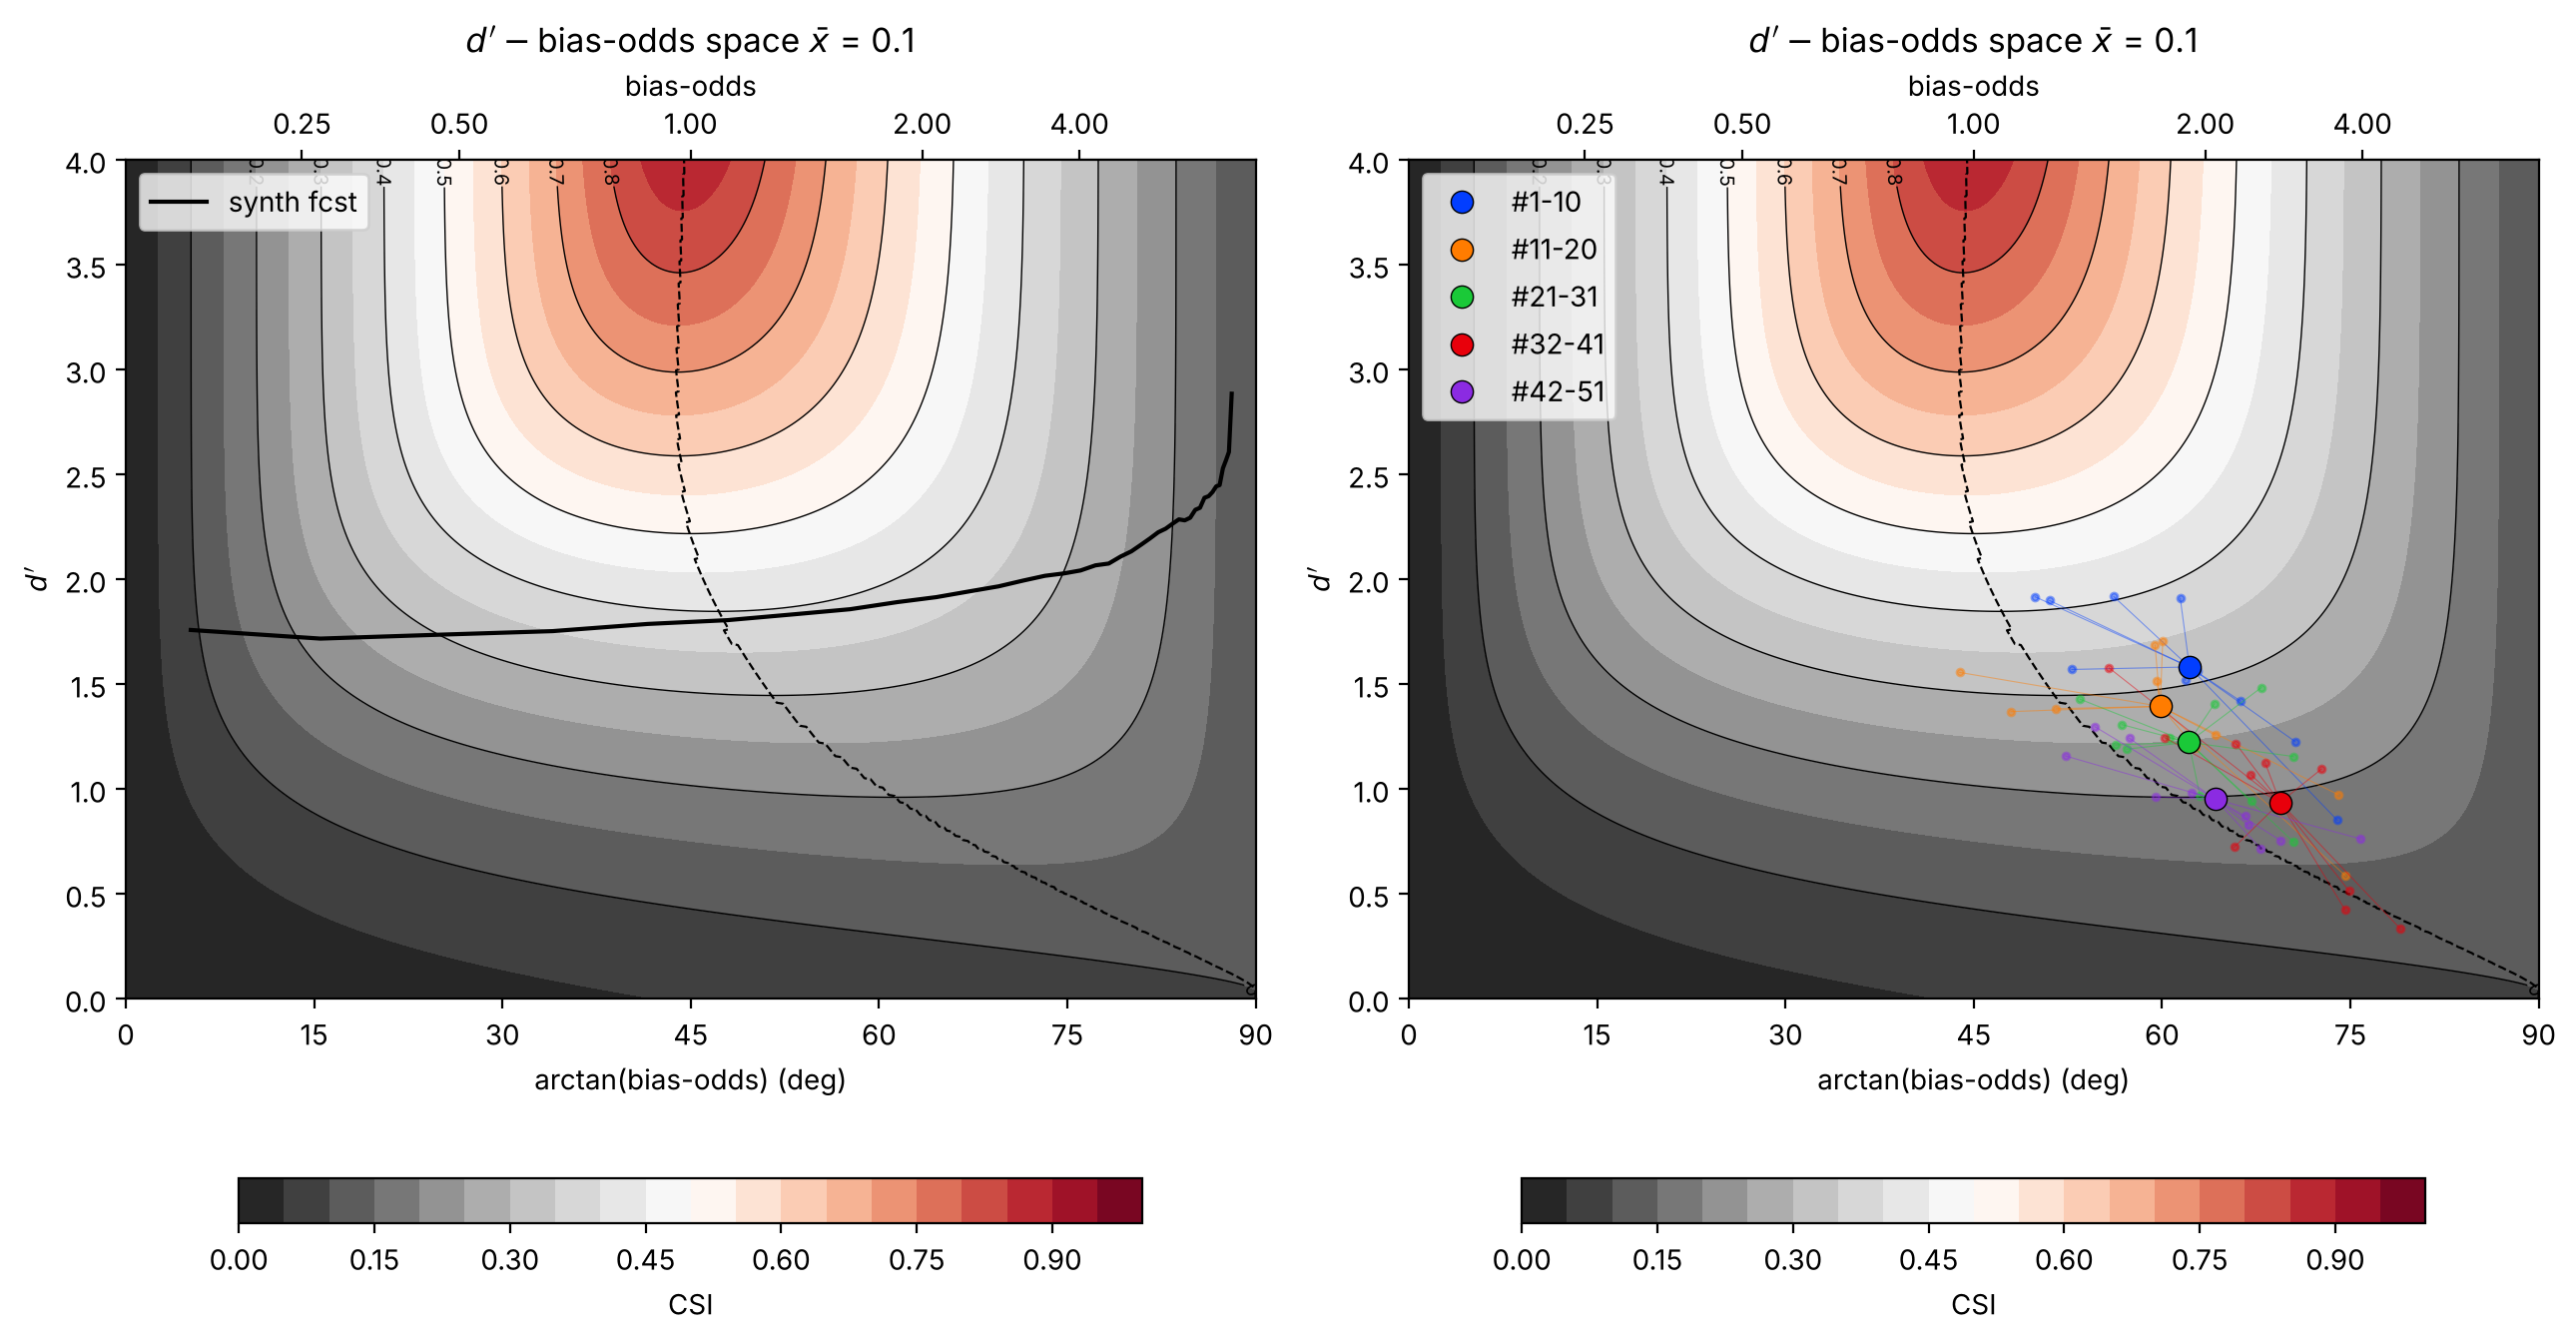

In [11]:
# d'-bias-odds space with CSI in the background (xbar = 0.1); dashed curve = CSI-maximizing threshold for each d'

def dprime_theta_grid(xbar):
    z=np.linspace(-6,6,1201); dps=np.linspace(0.001,4.,801)
    Z,DP=np.meshgrid(z,dps)
    P=norm.cdf(Z+DP/2); F=norm.cdf(Z-DP/2)
    a=xbar*P; b=(1-xbar)*F; c=xbar*(1-P); d=(1-xbar)*(1-F)
    TH=np.degrees(np.arctan(biasodds(a,b,c,d)))
    return TH,DP,dps,(a,b,c,d)

def dprime_theta_axes(ax,xbar,fill=csi,label='CSI'):
    TH,DP,dps,tab=dprime_theta_grid(xbar)
    Fv=fill(*tab)
    sc=ax.contourf(TH,DP,Fv,levels=np.linspace(0,1,21),cmap='RdGy_r')
    cs=ax.contour(TH,DP,Fv,levels=np.linspace(0.1,0.9,9),colors='k',linewidths=0.5); ax.clabel(cs,fontsize=7)
    imax=np.nanargmax(Fv,axis=1)
    ax.plot(TH[np.arange(len(dps)),imax],dps,'k--',lw=0.8)
    plt.colorbar(sc,ax=ax,orientation='horizontal',shrink=0.8,label=label)
    sec=ax.secondary_xaxis('top',functions=(lambda x: np.tan(np.radians(x)),lambda y: np.degrees(np.arctan(y))))
    sec.set_xticks([0.25,0.5,1,2,4]); sec.set_xlabel('bias-odds')
    ax.set(xlim=(0,90),ylim=(0,4),xlabel='arctan(bias-odds) (deg)',ylabel=r"$d'$")
    ax.set_xticks(range(0,91,15))
    ax.set_title(r"$d'-$bias-odds space $\bar x$ = "+f'{xbar}')

fig,axs=plt.subplots(1,2,figsize=(13,7))
dprime_theta_axes(axs[0],xbar)
axs[0].plot(df.THETA_BO,df.DPRIME,'k-',lw=1.5,label='synth fcst'); axs[0].legend(loc='upper left')
dprime_theta_axes(axs[1],xbar)
plot_groups(axs[1],off_x,grp_x,'THETA_BO','DPRIME'); axs[1].legend(loc='upper left')
plt.tight_layout()

The dashed curve marks, for each $d'$, the threshold that maximizes $CSI$; it moves toward over-forecasting as discrimination weakens. The synthetic forecasts (generated from a bivariate normal, then a beta transform) trace a curve that is not exactly horizontal, because their ROC curve is not exactly equal-variance binormal; the wiggles at the far right are sampling noise at the lowest thresholds, where very few "no" forecasts remain. The code below compares each warning-duration group with its CSI-maximizing threshold, assuming the equal-variance binormal curve through its point.

In [12]:
def csi_max_for_dprime(dp,xbar):
    z=np.linspace(-6,6,120001)
    P=norm.cdf(z+dp/2); F=norm.cdf(z-dp/2)
    a=xbar*P; b=(1-xbar)*F; c=xbar*(1-P)
    s=a/(a+b+c); i=np.argmax(s)
    return (a[i]+b[i])/xbar, s[i]

out=grp_x[['group','DPRIME','BIAS','CSI']].copy()
res=[csi_max_for_dprime(d,xbar) for d in out.DPRIME]
out['BIAS_at_max_CSI']=[r[0] for r in res]; out['max_CSI']=[r[1] for r in res]
out['group']=leg
out.round(3)

,group,DPRIME,BIAS,CSI,BIAS_at_max_CSI,max_CSI
0,#1-10,1.581,1.739,0.316,1.159,0.332
1,#11-20,1.393,1.606,0.283,1.259,0.288
2,#21-31,1.222,1.736,0.248,1.386,0.251
3,#32-41,0.935,2.282,0.192,1.720,0.196
4,#42-51,0.950,1.873,0.198,1.698,0.198


## displacement–bias-odds space (Baldwin and Kain 2006 circles)

The observed event is a circle of radius 1 (area ↔ $\bar x$) and the forecast is a circle of radius $\sqrt B$ (area ↔ $\bar xB$), with centers a distance $D$ apart (in units of the observed radius). Hits are the overlap (lens) area scaled by $\bar x/\pi$; for $|1-\sqrt B|<D<1+\sqrt B$:

$a=\frac{\bar x}{\pi}\left[\cos^{-1}\frac{D^2+1-B}{2D}+B\cos^{-1}\frac{D^2-1+B}{2D\sqrt B}-\tfrac12\sqrt{(\sqrt B+1-D)(\sqrt B-1+D)(1+D-\sqrt B)(\sqrt B+1+D)}\right]$

Outside that range: $a=0$ for $D\ge1+\sqrt B$ (no overlap), $a=\bar x$ for $D\le\sqrt B-1$ (observed circle inside the forecast), and $a=\bar xB$ for $D\le1-\sqrt B$ (forecast inside the observed). Then $b=\bar xB-a$, $c=\bar x-a$, $d=1-a-b-c$, and $\tan\theta=\frac{B(1-\bar x)}{1-\bar xB}$.

Perfect forecasts are at $D=0$, $\theta=45^{\circ}$ (skill falls going up). No-skill is the curve $a=\bar x^2B$ ($SR=\bar x$). The background is flat above $D=1+\sqrt B$ and below $D=|1-\sqrt B|$, where every point is the same table. Any table with $0<a<\bar x\min(1,B)$ maps to exactly one $D$ (the overlap shrinks steadily as $D$ grows), so real forecasts can be placed here, with $D$ read as the displacement an equivalent pair of circles would have.

In [13]:
def lens_a(B,D,xbar):
    r,R=1.,np.sqrt(B)
    if D>=r+R: return 0.
    if D<=R-r: return xbar
    if D<=r-R: return xbar*B
    A=(np.arccos((D*D+1-B)/(2*D))+B*np.arccos((D*D+B-1)/(2*D*R))
       -0.5*np.sqrt((-D+r+R)*(D+r-R)*(D-r+R)*(D+r+R)))
    return xbar*A/np.pi

def displacement(B,a,xbar):
    # D that gives hit proportion a (unique in the partial-overlap range)
    return brentq(lambda D: lens_a(B,D,xbar)-a,abs(1-np.sqrt(B))+1e-12,1+np.sqrt(B)-1e-12,xtol=1e-14)

# check: lens area against Monte Carlo
pts=rng.uniform(-1,1,size=(2000000,2)); inside=(pts**2).sum(1)<=1
for Bv,Dv in [(1.,0.5),(2.,1.2),(0.5,0.8)]:
    mc=np.mean(inside&(((pts[:,0]-Dv)**2+pts[:,1]**2)<=Bv))*4/np.pi
    print(f'B={Bv}, D={Dv}: formula {lens_a(Bv,Dv,1.):.4f}, Monte Carlo {mc:.4f}')
# check: round trip table -> D -> table
sel=rng.choice(len(ta),300,replace=False)
Bs=bias(ta,tb,tc,td)[sel]; xs=(ta+tc)[sel]
res=[abs(lens_a(Bs[k],displacement(Bs[k],ta[sel][k],xs[k]),xs[k])-ta[sel][k]) for k in range(len(sel))]
print('every table maps to a displacement D (max residual):',f'{max(res):.1e}')

off_x['D']=[displacement(B,a,xbar) for B,a in zip(off_x.BIAS,off_x.a)]
grp_x['D']=[displacement(B,a,xbar) for B,a in zip(grp_x.BIAS,grp_x.a)]
# synthetic forecasts: use their own sample base rate; keep thresholds in the partial-overlap range
xs_syn=df.a+df.c
df_ok=df[(df.a>0)&(df.a<xs_syn*np.minimum(1.,df.BIAS)*(1.-1e-9))].copy()
df_ok['D']=[displacement(B,a,x) for B,a,x in zip(df_ok.BIAS,df_ok.a,df_ok.a+df_ok.c)]

B=1.0, D=0.5: formula 0.6850, Monte Carlo 0.6857
B=2.0, D=1.2: formula 0.5551, Monte Carlo 0.5554
B=0.5, D=0.8: formula 0.2991, Monte Carlo 0.2997
every table maps to a displacement D (max residual): 1.8e-15


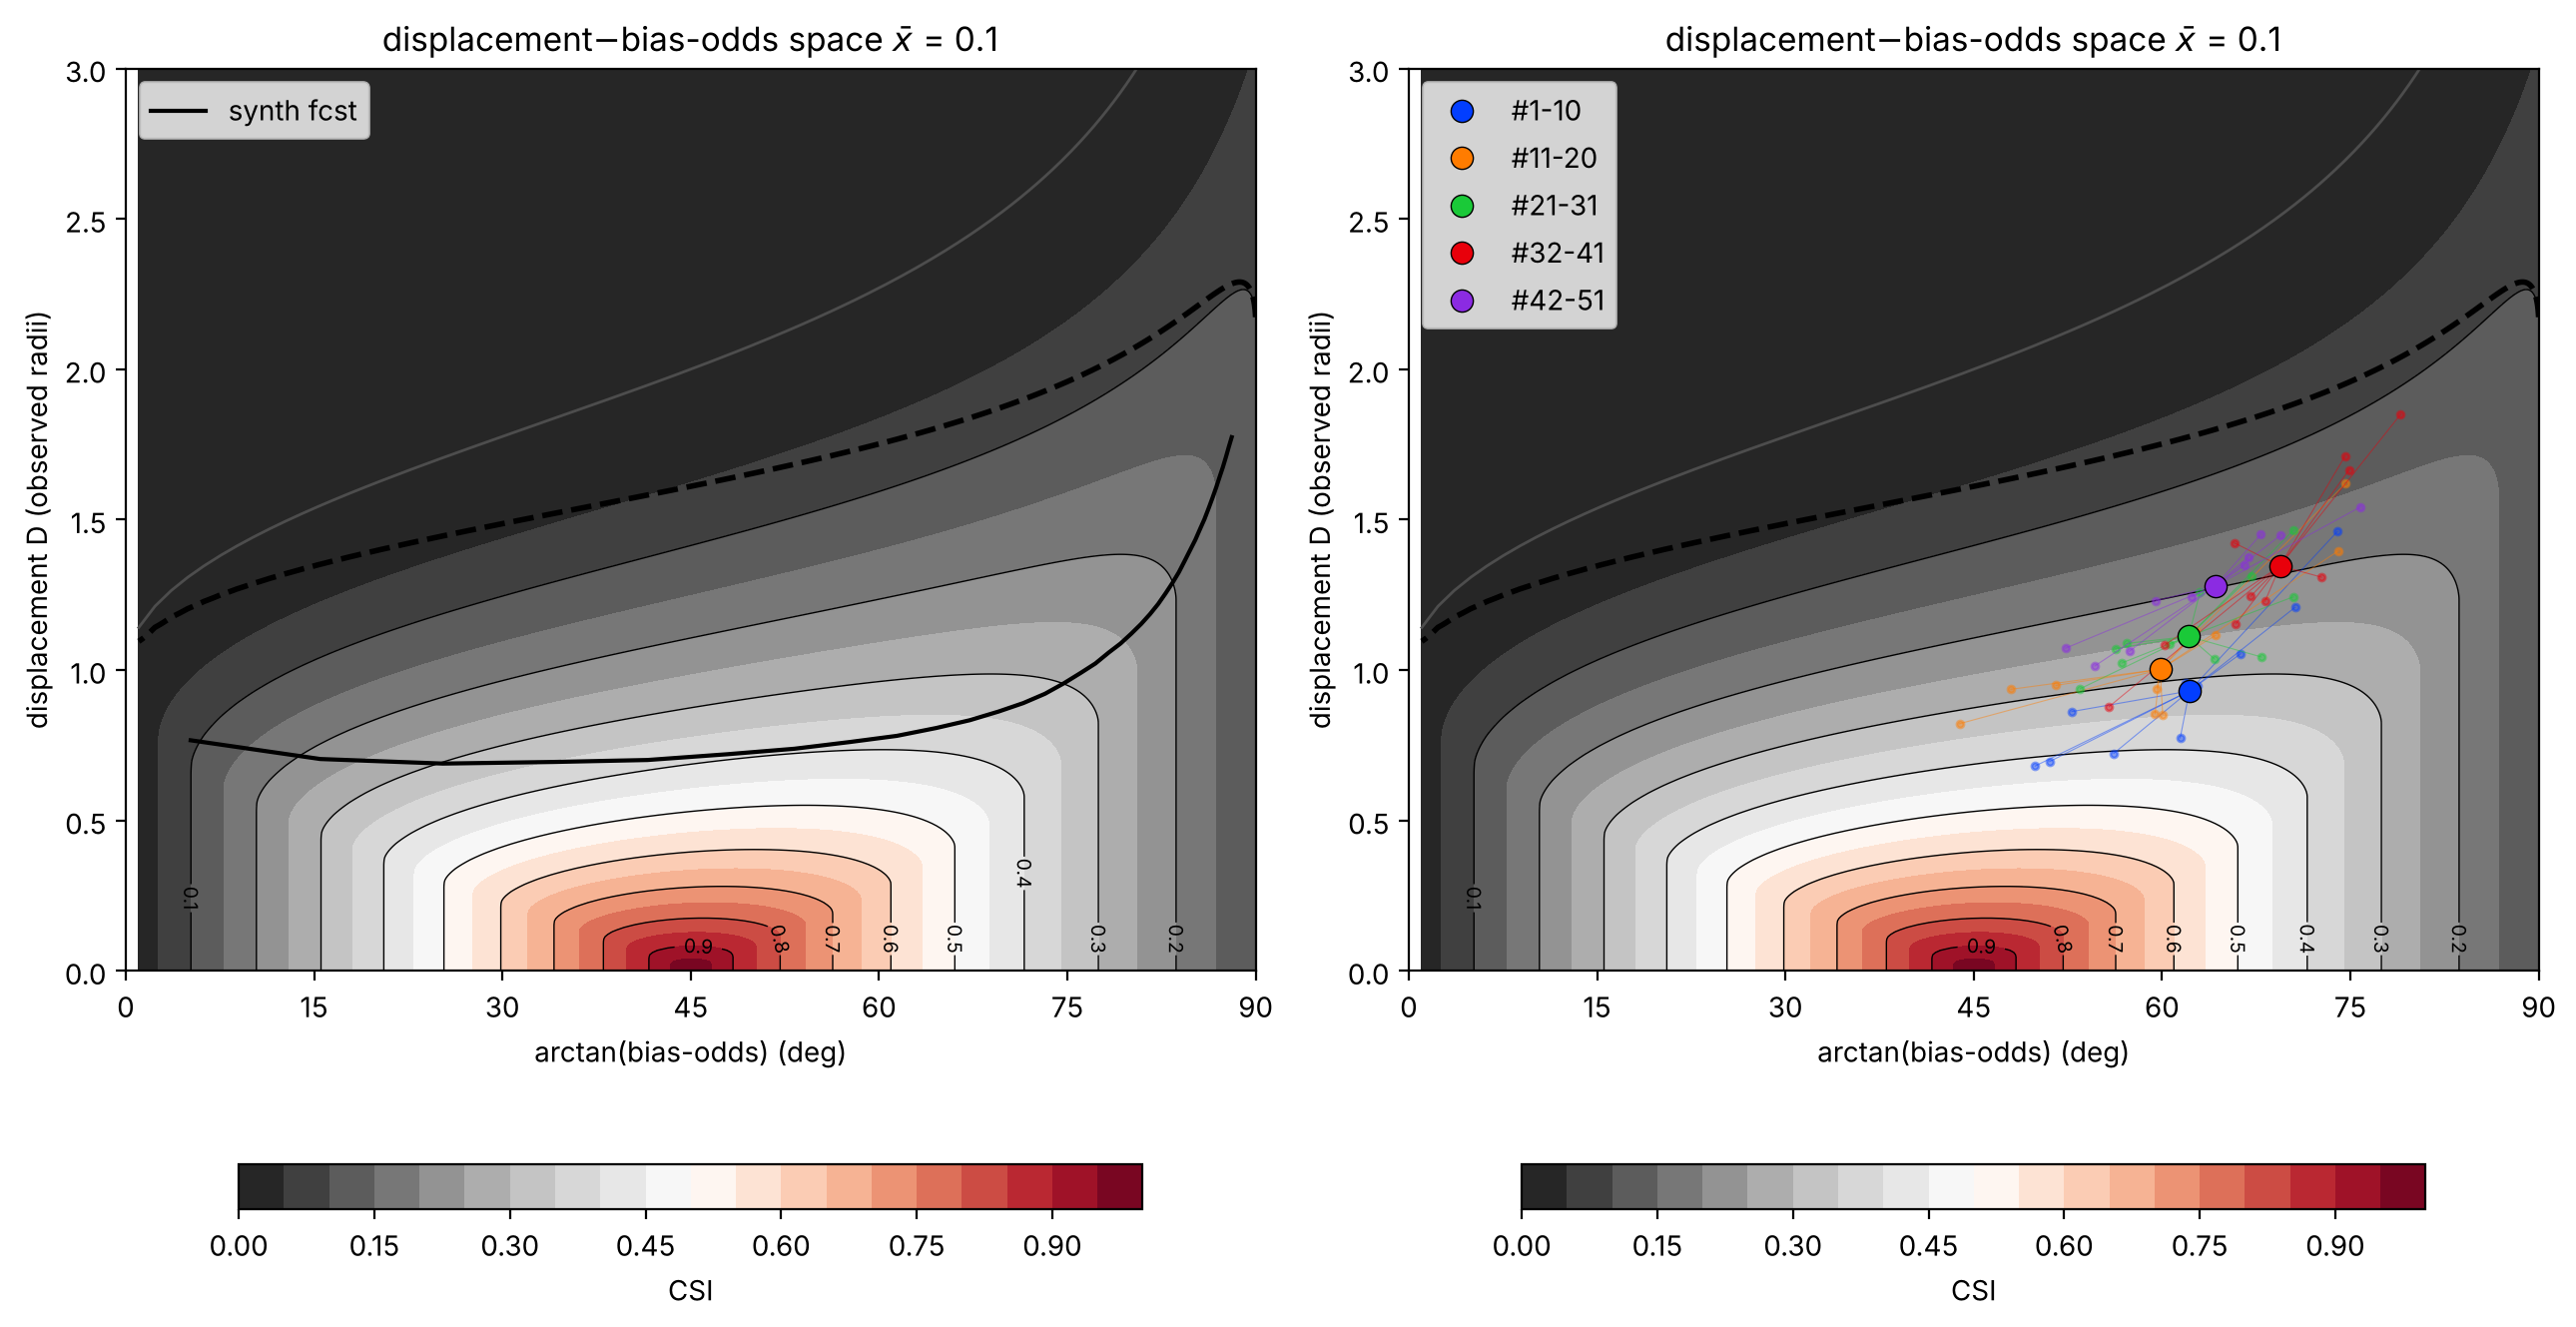

In [14]:
# displacement-bias-odds space with CSI in the background (xbar = 0.1)

def disp_theta_axes(ax,xbar,fill=csi,label='CSI'):
    Bg=np.linspace(0.02,0.999/xbar,400); Dg=np.linspace(0.001,3.0,400)
    A=np.array([[lens_a(Bv,Dv,xbar) for Bv in Bg] for Dv in Dg])
    Bb=xbar*Bg[None,:]-A; C=xbar-A; Dd=1-A-Bb-C
    TH=np.degrees(np.arctan(Bg*(1-xbar)/(1-xbar*Bg)))
    Fv=fill(A,Bb,C,Dd)
    sc=ax.contourf(TH,Dg,Fv,levels=np.linspace(0,1,21),cmap='RdGy_r')
    cs=ax.contour(TH,Dg,Fv,levels=np.linspace(0.1,0.9,9),colors='k',linewidths=0.5); ax.clabel(cs,fontsize=7)
    ax.contour(TH,Dg,A/(A+Bb),levels=[xbar],colors='k',linewidths=2,linestyles='dashed')   # no skill
    ax.plot(TH,1+np.sqrt(Bg),color='0.3',lw=1)                                           # no overlap above
    plt.colorbar(sc,ax=ax,orientation='horizontal',shrink=0.8,label=label)
    ax.set(xlim=(0,90),ylim=(0,3),xlabel='arctan(bias-odds) (deg)',ylabel='displacement D (observed radii)')
    ax.set_xticks(range(0,91,15))
    ax.set_title(r'displacement$-$bias-odds space $\bar x$ = '+f'{xbar}')

fig,axs=plt.subplots(1,2,figsize=(13,7))
disp_theta_axes(axs[0],xbar)
axs[0].plot(df_ok.THETA_BO,df_ok.D,'k-',lw=1.5,label='synth fcst'); axs[0].legend(loc='upper left')
disp_theta_axes(axs[1],xbar)
plot_groups(axs[1],off_x,grp_x,'THETA_BO','D'); axs[1].legend(loc='upper left')
plt.tight_layout()

## sensitivity to the assumed base rate

NWS reports POD and FAR without a base rate, so an assumed $\bar x$ is needed to estimate POFD and every quantity that depends on the correct nulls. Brooks (2004) defines $\bar x$ through stratification: the fraction of "difficult" warning situations (those requiring a decision) that produce a tornado. He argues $\bar x<0.01$ is unlikely (about the tornado probability for any detected mesocyclone) and that $\bar x$ is more likely on the order of 0.1. With POD and FAR alone, each (POD, FAR) point is consistent with a whole curve of $(D',\bar x)$ pairs (his Fig. 3), and $\bar x$ likely varies by location, season, and year.

Quantities that need no $\bar x$: POD, SR, bias, CSI, and positions on the performance diagram and in CSI–bias space. Everything else changes with $\bar x$. The code below repeats the group analysis for $\bar x$ from 0.01 to 0.2 (0.2 is an arbitrary upper value chosen here).

In [15]:
rows=[]
for xb in [0.01,0.02,0.05,0.1,0.15,0.2]:
    g=add_scores(groups,xb)
    cm=[csi_max_for_dprime(d,xb) for d in g.DPRIME]
    over=np.all(g.BIAS.values>np.array([c[0] for c in cm]))
    rows.append({'xbar':xb,
                 "d' by group":np.round(g.DPRIME.values,2).tolist(),
                 "rank by d'":'-'.join(str(i+1) for i in np.argsort(-g.DPRIME.values)),
                 'rank by phi':'-'.join(str(i+1) for i in np.argsort(-g.PHI.values)),
                 "d' gap #1-10 minus #42-51":np.round(g.DPRIME.values[0]-g.DPRIME.values[4],2),
                 'all groups over-forecast vs CSI-max':bool(over),
                 'offices with SR <= xbar (negative skill)':int((offices.SR<=xb).sum())})
pd.set_option('display.max_colwidth',60)
pd.DataFrame(rows)

,xbar,d' by group,rank by d',rank by phi,d' gap #1-10 minus #42-51,all groups over-forecast vs CSI-max,offices with SR <= xbar (negative skill)
0,0.01,"[2.7, 2.5, 2.36, 2.18, 2.13]",1-2-3-4-5,1-2-3-4-5,0.57,True,0
1,0.02,"[2.42, 2.22, 2.08, 1.88, 1.84]",1-2-3-4-5,1-2-3-4-5,0.58,True,0
2,0.05,"[1.99, 1.8, 1.64, 1.4, 1.39]",1-2-3-4-5,1-2-3-5-4,0.60,True,0
3,0.10,"[1.58, 1.39, 1.22, 0.93, 0.95]",1-2-3-5-4,1-2-3-5-4,0.63,True,0
4,0.15,"[1.28, 1.1, 0.91, 0.57, 0.62]",1-2-3-5-4,1-2-3-5-4,0.66,False,2
5,0.20,"[1.02, 0.84, 0.64, 0.23, 0.32]",1-2-3-5-4,1-2-3-5-4,0.70,False,5


In [16]:
# how different would the groups' base rates have to be to erase the d' gap between #1-10 and #42-51?
def dp_at(podv,srv,xb):
    g=add_scores(pd.DataFrame({'POD':[podv],'SR':[srv]}),xb)
    return g.DPRIME.values[0]
g1=groups.iloc[0]; g5=groups.iloc[4]
d1=dp_at(g1.POD,g1.SR,0.1); d5=dp_at(g5.POD,g5.SR,0.1)
x1=brentq(lambda xb: dp_at(g1.POD,g1.SR,xb)-d5,0.1,0.3)
x5=brentq(lambda xb: dp_at(g5.POD,g5.SR,xb)-d1,0.005,0.1)
print(f"at xbar=0.1: d' = {d1:.2f} (#1-10) and {d5:.2f} (#42-51)")
print(f"gap erased if #1-10 had xbar = {x1:.3f} (others 0.1), or #42-51 had xbar = {x5:.3f}")

at xbar=0.1: d' = 1.58 (#1-10) and 0.95 (#42-51)
gap erased if #1-10 had xbar = 0.213 (others 0.1), or #42-51 had xbar = 0.035


The level of $d'$ is not robust to $\bar x$, but the comparison between groups mostly is: the top three groups keep their order at every $\bar x$ tested, and the $d'$ gap between the shortest- and longest-duration groups stays between about 0.57 and 0.70 (unless the groups' true base rates differ by a factor of about 2–3). Groups #32-41 and #42-51 swap places and are best treated as tied. The result that every group over-forecasts relative to its CSI-maximizing threshold holds for $\bar x\le0.1$ but not at 0.15 or 0.2, so it should not be stated without that condition.

## prior work and related displays

- Hogan and Mason (2012) skill–bias diagrams, and Slocum et al. (2023, appendix Fig. A1), which plots $HSS$ against frequency bias with $F_1$ shading at base rates of 5–40%, built by mapping a grid of hit rate $H$ and false alarm rate $F$ forward using Hogan and Mason's $(s,H,F)$ form of the 2x2 table. CSI–bias space is the same kind of display; writing the table in closed form in the plotted coordinates (as here) is a small algebraic step.
- Signal detection theory plots sensitivity against response bias (isosensitivity and isobias curves). The $d'$ space here differs by measuring bias with the forecast frequency (bias-odds) rather than the SDT decision criterion.
- Baldwin and Kain (2006) plotted performance measures as functions of displacement, bias, and event frequency for the two-circle model.

## references

Baldwin, M. E., and J. S. Kain, 2006: Sensitivity of several performance measures to displacement error, bias, and event frequency. Wea. Forecasting, 21, 636–648.

Boyd, K., V. S. Costa, J. Davis, and D. Page, 2012: Unachievable region in precision-recall space and its effect on empirical evaluation. https://arxiv.org/abs/1206.4667

Brooks, H. E., 2004: Tornado-warning performance in the past and future: A perspective from signal detection theory. Bull. Amer. Meteor. Soc., 85, 837–843, https://doi.org/10.1175/BAMS-85-6-837.

Hogan, R. J., and I. B. Mason, 2012: Deterministic forecasts of binary events. Forecast Verification: A Practitioner's Guide in Atmospheric Science, 2nd ed., I. T. Jolliffe and D. B. Stephenson, Eds., Wiley, 31–59, https://doi.org/10.1002/9781119960003.ch3.

Roebber, P. J., 2009: Visualizing multiple measures of forecast quality. Wea. Forecasting, 24, https://doi.org/10.1175/2008WAF2222159.1.

Slocum, C. J., J. A. Knaff, and S. N. Stevenson, 2023: Lightning-based tropical cyclone rapid intensification guidance. Wea. Forecasting, 38, 1209–1227, https://doi.org/10.1175/WAF-D-22-0157.1.